# COSYNE abstract figures v2

Generate individual plots here, then assemble the four-row figures in Inkscape. Imports and visual styling follow `cosyne_abstract_figures.ipynb`.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path
import importlib
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

NOTEBOOKS_DIR = Path.cwd().resolve()
if not (NOTEBOOKS_DIR / "cosyne_abstract_figures.py").exists():
    candidate = NOTEBOOKS_DIR / "notebooks"
    if (candidate / "cosyne_abstract_figures.py").exists():
        NOTEBOOKS_DIR = candidate
if str(NOTEBOOKS_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOKS_DIR))

import cosyne_abstract_figures as caf
caf = importlib.reload(caf)
from cosyne_abstract_figures import *

%config InlineBackend.figure_format = 'retina'
print(f"Figure code: {NOTEBOOKS_DIR / 'cosyne_abstract_figures.py'}")

Figure code: /media/labuser/NA_1_2025/spyglass_common/notebooks/cosyne_abstract_figures.py


## Plot style

Use the original figure helper's palette and Matplotlib style for each standalone plot. Set each plot's final physical size when creating that plot.

In [3]:
FIGURE_COLORS = COLORS.copy()
FIGURE_STYLE = caf._style_parameters()
FIGURE_STYLE.update({
    "axes.labelsize": FIGURE_STYLE["font.size"] / 2,
    "xtick.labelsize": FIGURE_STYLE["font.size"] / 2,
    "ytick.labelsize": FIGURE_STYLE["font.size"] / 2,
})
plt.rcParams.update(FIGURE_STYLE)

## W-track: one trial colored by speed

Select a trial, then click Save SVG to write it to `/home/labuser/Documents/lab-notebook/presentations/Cosyne/`. The dense speed overlay is rasterized; the track, nodes, colorbar, and text remain editable vectors.

In [4]:
import cosyne_abstract_figures_v2 as caf2
caf2 = importlib.reload(caf2)
from cosyne_abstract_figures_v2 import *

ANIMAL = "Wilbur"  # Change to "Senor" and rerun this cell.
trial_dropdown = show_wtrack_trial_selector(ANIMAL)

## W-track: one trial colored by angular velocity

In [5]:
ANIMAL = "Wilbur"  # Change to "Senor" and rerun this cell.
angular_velocity_trial_dropdown = show_wtrack_angular_velocity_trial_selector(ANIMAL)

## Gait phase

Reference-paw (forepawR) speed with accepted touchdowns, and the resulting gait phase, over a short window of continuous running. Sized 180 × 28 mm for one full-width row. The first call derives phase from DLC pose (read-only DB fetch, as in `movement_groups_encoding.ipynb`) and caches it in `cosyne_cache/`.

## W-track: one trial colored by gait phase

Wilbur only (forepawR phase). Grey path segments fall outside accepted strides, where phase is undefined. The first call derives phase from DLC pose and caches it in `cosyne_cache/`.

In [6]:
gait_phase_trial_dropdown = caf2.show_wtrack_gait_phase_trial_selector("Wilbur")

## W-track colored by speed with a trial-progress arrow, and speed vs progress

One trial drives both plots: the W-track colored by speed with a 0→1 trial-progress arrow, and speed against trial progress beneath it. Save SVGs writes each as its own file.

In [18]:
ANIMAL = "Wilbur"  # Change to "Senor" and rerun this cell.
SMOOTHING_SIGMA = 5.0  # Gaussian sigma in samples for the speed profile; 0 = raw.
PROFILE_HEIGHT_IN = 0.8  # Height of the speed-vs-progress plot, in inches.
progress_speed_trial_dropdown = caf2.show_wtrack_progress_speed_selector(ANIMAL, smoothing_sigma=SMOOTHING_SIGMA, profile_height_in=PROFILE_HEIGHT_IN)

## Progress profiles per animal, normalized to each animal's maximum

Saved Figure 1B mean curves, each divided by that animal's own maximum for the variable. The maximum, in original units, is printed above the plot in the animal's color (Wilbur, Senor, J from left to right).

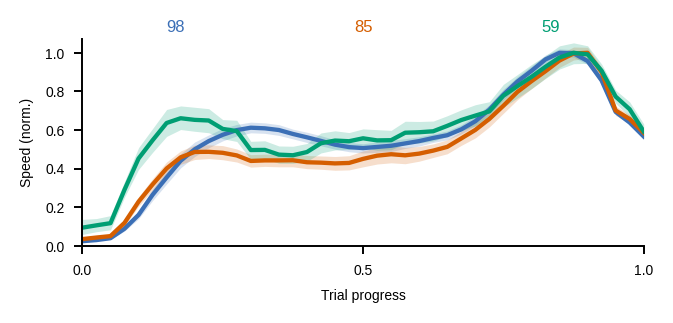

n_trials per progress bin (speed):
        n_trials_min  n_trials_max
animal                            
Wilbur           124           201
Senor            102           241
J                 99           109
Saved SVG: /home/labuser/Documents/lab-notebook/presentations/Cosyne/cosyne_normalized_speed_vs_progress.svg


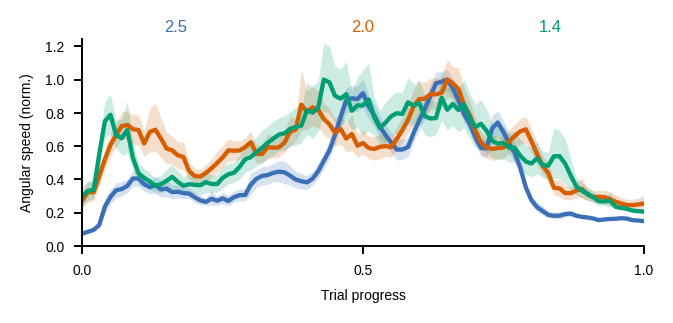

n_trials per progress bin (abs_body_angular_velocity_rad_s):
        n_trials_min  n_trials_max
animal                            
Wilbur           103           191
Senor            104           239
J                 69           107
Saved SVG: /home/labuser/Documents/lab-notebook/presentations/Cosyne/cosyne_normalized_abs_body_angular_velocity_rad_s_vs_progress.svg


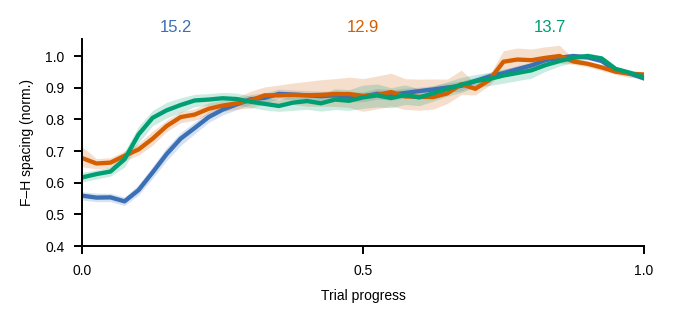

n_trials per progress bin (mean_fore_hind_spacing):
        n_trials_min  n_trials_max
animal                            
Wilbur           118           194
Senor            125           243
J                 91           108
Saved SVG: /home/labuser/Documents/lab-notebook/presentations/Cosyne/cosyne_normalized_mean_fore_hind_spacing_vs_progress.svg


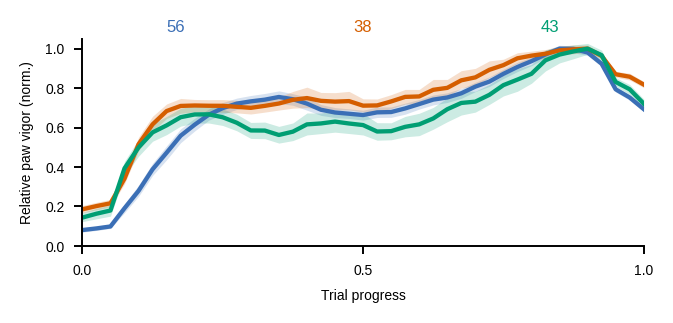

n_trials per progress bin (relative_paw_vigor):
        n_trials_min  n_trials_max
animal                            
Wilbur           118           194
Senor            123           241
J                 89           108
Saved SVG: /home/labuser/Documents/lab-notebook/presentations/Cosyne/cosyne_normalized_relative_paw_vigor_vs_progress.svg


In [24]:
NORMALIZE = True  # True: divide each animal by its own maximum; False: original units.
SHOW_CI = True  # True: add the 5th-95th percentile of the trial bootstrap.
RUN_MASK = False  # True: run-zone samples only; False: all outbound/inbound samples.
SAVE_SVG = True  # Set True to write each plot to the Cosyne folder.
for variable in caf2.NORMALIZED_PROFILE_SPECS:
    fig = caf2.plot_normalized_progress_profile(variable, normalize=NORMALIZE, show_ci=SHOW_CI, run_mask=RUN_MASK)
    plt.show()
    print(f"n_trials per progress bin ({variable}):")
    print(caf2.progress_profile_trial_counts(variable, run_mask=RUN_MASK).to_string())
    if SAVE_SVG:
        print(f"Saved SVG: {caf2.save_normalized_progress_profile_svg(variable, normalize=NORMALIZE, show_ci=SHOW_CI, run_mask=RUN_MASK)}")

## Predictability of behavioral variables from trial progress

Saved Figure 1C scores: cross-validated R² of each variable predicted from trial progress (spline + ridge, trial-grouped 5-fold CV), averaged equally across Wilbur, Senor and J.

In [13]:
progress_predictability_scores = caf.mean_animal_progress_r2(caf.load_multi_animal_progress_r2())
progress_predictability_scores.round(3).sort_values(ascending=False)

Speed                  0.290
Acceleration           0.161
Angular speed          0.151
Relative paw vigor     0.084
Fore–hind spacing      0.076
Mean stance width      0.041
Fore − hind width      0.015
Fore − hind vigor      0.014
Lateral phase (sin)    0.007
Spacing asymmetry      0.002
Gait phase (sin)       0.001
Gait phase (cos)      -0.000
Lateral phase (cos)   -0.000
dtype: float64

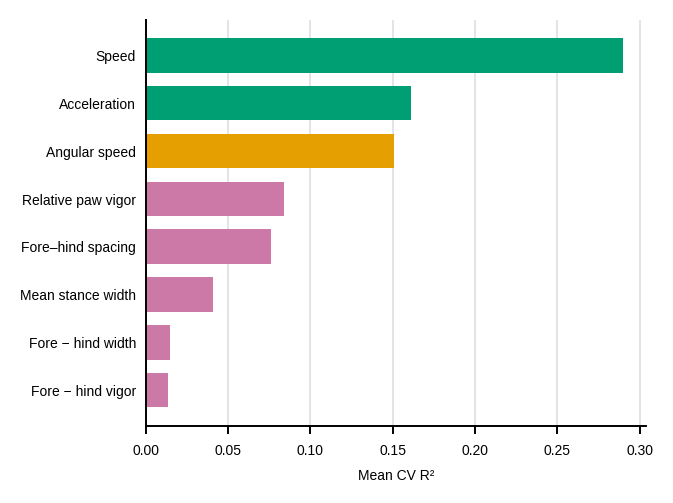

Saved SVG: /home/labuser/Documents/lab-notebook/presentations/Cosyne/cosyne_progress_predictability.svg


In [17]:
TRUNCATE = True  # True: drop all bars ranked below LAST_VARIABLE.
LAST_VARIABLE = "Fore − hind vigor"  # Last bar kept when TRUNCATE is True.
SAVE_SVG = True  # Set True to write the plot to the Cosyne folder.
plot_options = dict(truncate=TRUNCATE, last_variable=LAST_VARIABLE)
fig = caf2.plot_progress_predictability(progress_predictability_scores, **plot_options)
plt.show()
if SAVE_SVG:
    print(f"Saved SVG: {caf2.save_progress_predictability_svg(progress_predictability_scores, **plot_options)}")

## Wilbur: observed vs model-fit profiles over trial progress

Speed, absolute angular velocity and fore–hind spacing against trial progress as three stacked rows sharing one x-axis (the legend is in the top plot). Observed: the saved Figure 1B trial-mean curve. Model fit: the spline + ridge fit on progress used for the predictability analysis (the defaults of `summarize_progress_predictability`), fitted here on all samples.

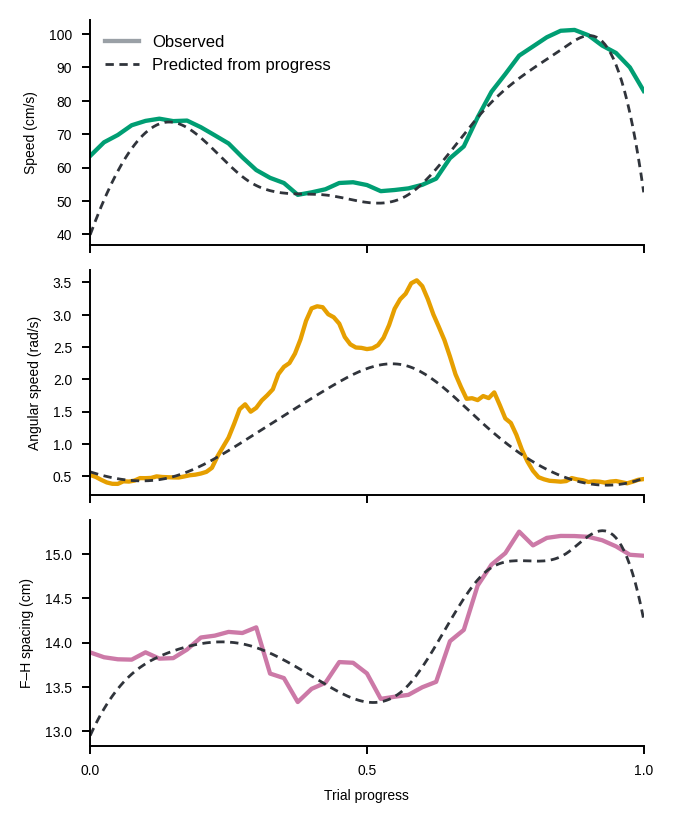

Saved SVG: /home/labuser/Documents/lab-notebook/presentations/Cosyne/cosyne_progress_fit_grid_wilbur.svg


In [15]:
SAVE_SVG = True  # Set True to write the grid to the Cosyne folder.
fig = caf2.plot_progress_fit_grid()
plt.show()
if SAVE_SVG:
    print(f"Saved SVG: {caf2.save_progress_fit_grid_svg()}")